# Session 31 Solutions: Linear Regression: Your First Model

Data Science with Python, Level 2, Stage 5: ML Fundamentals

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
flats = pd.read_csv(DATA_URL + "apartments.csv")

## In-Class Exercises

### In-Class Exercise 1: One Feature at a Time

In [2]:
for f in ["rooms", "building_age", "distance_center_km"]:
    m = LinearRegression().fit(flats[[f]], flats["price_k"])
    print(f, round(m.score(flats[[f]], flats["price_k"]), 3))

rooms 0.273
building_age 0.042
distance_center_km 0.209


### In-Class Exercise 2: Predict Your Flat

In [3]:
features = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
X_train, X_test, y_train, y_test = train_test_split(flats[features], flats["price_k"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_train, y_train)
new = pd.DataFrame([{"area_m2": 90, "rooms": 3, "building_age": 10, "distance_center_km": 4, "elevator": True, "parking": False}])
print(m.predict(new).round(1))

[107.6]


### In-Class Exercise 3: Biggest Errors

In [4]:
features = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
X_train, X_test, y_train, y_test = train_test_split(flats[features], flats["price_k"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_train, y_train)
errors = (y_test - m.predict(X_test)).abs()
flats.loc[errors.nlargest(5).index, ["district", "area_m2", "price_k"]]

,district,area_m2,price_k
719,Westpark,115,202.2
54,Westpark,68,137.5
787,Riverside,35,52.5
360,Old Town,57,78.3
393,Westpark,137,88.3


### In-Class Exercise 4: Different Split

In [5]:
features = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
for rs in [1, 2, 3]:
    a, b, c, d = train_test_split(flats[features], flats["price_k"], test_size=0.2, random_state=rs)
    print(rs, round(LinearRegression().fit(a, c).score(b, d), 3))

1 0.884
2 0.848
3 0.645


## Part A: Basic

### Exercise 1: Study Hours and Scores

In [6]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
m = LinearRegression().fit(exams[["study_hours_week"]], exams["math"])
print(round(m.coef_[0], 2), round(m.intercept_, 2), round(m.score(exams[["study_hours_week"]], exams["math"]), 3))
# Each extra hour of study per week goes with about 1.5 more points in math, on average.

1.52 46.23 0.216


### Exercise 2: Bike Rentals and Temperature

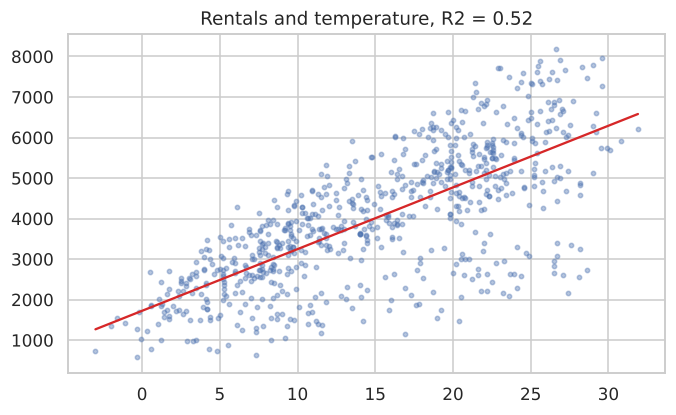

In [7]:
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
m = LinearRegression().fit(bikes[["temp_c"]], bikes["rentals"])
xs = pd.DataFrame({"temp_c": np.linspace(bikes["temp_c"].min(), bikes["temp_c"].max(), 50)})
plt.scatter(bikes["temp_c"], bikes["rentals"], s=8, alpha=0.4)
plt.plot(xs["temp_c"], m.predict(xs), color="tab:red")
plt.title(f"Rentals and temperature, R2 = {m.score(bikes[['temp_c']], bikes['rentals']):.2f}")
plt.show()

## Part B: Intermediate

### Exercise 3: Several Features for Exams

In [8]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
X = exams[["study_hours_week", "sleep_hours", "attendance_pct"]]
X_train, X_test, y_train, y_test = train_test_split(X, exams["math"], test_size=0.2, random_state=0)
m = LinearRegression().fit(X_train, y_train)
print(pd.Series(m.coef_, index=X.columns).round(2))
pred = m.predict(X_test)
print(round(r2_score(y_test, pred), 3), round(mean_absolute_error(y_test, pred), 2))

study_hours_week    1.36
sleep_hours         2.58
attendance_pct      0.13
dtype: float64
0.311 8.61


### Exercise 4: Residual Plot

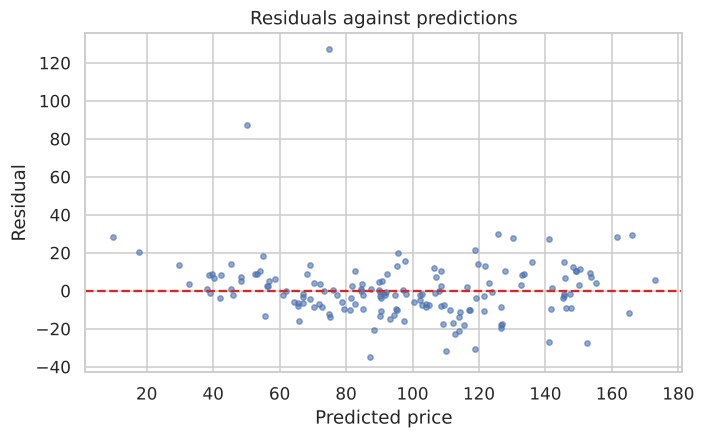

In [9]:
features = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
X_train, X_test, y_train, y_test = train_test_split(flats[features], flats["price_k"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_train, y_train)
pred = m.predict(X_test)
plt.scatter(pred, y_test - pred, s=12, alpha=0.6)
plt.axhline(0, color="tab:red", linestyle="--")
plt.title("Residuals against predictions")
plt.xlabel("Predicted price")
plt.ylabel("Residual")
plt.show()
# Most residuals are close to zero, but a few large positive ones are luxury flats the model cannot explain.

## Part C: Challenge

### Exercise 5: Price per Square Metre by District

`drop_first=True` leaves out one district, which becomes the baseline; each coefficient compares a district with it. Session 36 covers this encoding properly.

In [10]:
features = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
dummies = pd.get_dummies(flats["district"], drop_first=True)
X = pd.concat([flats[features], dummies], axis=1)
X_train, X_test, y_train, y_test = train_test_split(X, flats["price_k"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_train, y_train)
print("Test R2:", round(m.score(X_test, y_test), 3))
print(pd.Series(m.coef_, index=X.columns)[dummies.columns].round(1))

Test R2: 0.823
Northgate   -14.9
Old Town     33.2
Riverside    19.0
Westpark    -21.8
dtype: float64


## Part D: Cumulative Project: Apartment Prices

### Exercise 6: Apartment Prices: A First Model

In [11]:
features_all = ["area_m2", "rooms", "floor", "building_age", "distance_center_km", "elevator", "parking"]
X_train, X_test, y_train, y_test = train_test_split(flats[features_all], flats["price_k"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_train, y_train)
pred = m.predict(X_test)
print("R2:", round(r2_score(y_test, pred), 3), "MAE:", round(mean_absolute_error(y_test, pred), 2))
baseline = np.full(len(y_test), y_train.mean())
print("Baseline MAE:", round(mean_absolute_error(y_test, baseline), 2))
coefs = pd.Series(m.coef_, index=features_all)
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(3).round(2))
# Each kilometre further from the centre lowers the predicted price by about 8 thousand, all else equal.

R2: 0.781 MAE: 10.75
Baseline MAE: 30.03
elevator              9.64
parking               9.57
distance_center_km   -7.91
dtype: float64


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Features go in; the target is what we predict. |
| 2 | B | Features are always a 2D table, even with one column. |
| 3 | B | Scores on training data are too optimistic. |
| 4 | B | It is the change in the prediction per km, holding the other features fixed. |
| 5 | B | MAE is the average absolute error, in the target's units. |